# Xử lý dữ liệu: chia train/test, học tham số chỉ từ train

**Đầu vào:** `preprocess_data.csv` (đã làm sạch bằng quy tắc cứng, còn giá trị thiếu) &nbsp;→&nbsp; **Đầu ra:** `train_data.csv`, `test_data.csv`, `../model/data_transformers.joblib`

Notebook này làm mọi bước **học tham số từ dữ liệu**. Nguyên tắc duy nhất:

> **`fit` trên train, `transform` mọi thứ.** Tập test chỉ được biến đổi bằng tham số đã học từ train, không bao giờ góp phần tạo ra tham số.

| Bước | Tham số học từ train | Áp lên test |
|---|---|---|
| 1. Chia train/test | (không) | |
| 2. Lọc giá trả trước / đặt cọc | bảng trung vị giá theo hãng-dòng-năm | đánh dấu theo bảng của train |
| 3. Điền thiếu (`CarImputer`) | trung vị km theo đời xe, mode kiểu dáng / số chỗ theo dòng xe, theo hãng | điền bằng đúng các giá trị đó |
| 3. Gộp nhãn hiếm (`BrandModelGrouper`) | danh sách hãng ≥ 30 tin, dòng xe ≥ 10 tin | nhãn lạ rơi về nhóm "khác" |
| 4. Đặc trưng cho Ridge | (công thức, không học) | |
| 5. Thí nghiệm chọn cách gộp nhãn, thử vị trí | CV chỉ trên train | không dùng test |
| 6. Đối chứng: điền sẵn so với điền trong từng fold | CV chỉ trên train | không dùng test |

Mã hóa one-hot và chuẩn hóa phụ thuộc mô hình nên làm ở `model.ipynb` (cũng fit trên train).

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from car_transformers import CarImputer, BrandModelGrouper
from report_utils import SLIDE_RC, save_slide, save_table, start_tables, update_numbers, vn

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9aa0a6"
LIGHT_BLUE, LIGHT_ORANGE = "#8fb8ee", "#f4a98a"

RANDOM_STATE = 42
SEG_BINS = [0, 200, 500, 1000, 2000, np.inf]
SEG_LABELS = ["< 200 triệu", "200-500", "500-1.000", "1-2 tỷ", "> 2 tỷ"]

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
start_tables("process")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## 1. Đọc dữ liệu và chia train/test

**Vì sao chia phân tầng theo phân khúc giá?** Giá lệch rất mạnh: xe trên 2 tỷ chỉ khoảng 3% số tin. Chia ngẫu nhiên thông thường có thể để tập test gần như không có xe trên 2 tỷ, khiến điểm đánh giá nhìn đẹp nhưng không phản ánh khả năng với xe sang. Chia **phân tầng** (`stratify`) theo 5 phân khúc giá đảm bảo mỗi phân khúc có cùng tỉ lệ ở train và test. Tập test giữ nguyên phân phối thật, không cân bằng lại.

Tỉ lệ 80/20 và `random_state = 42` giữ nguyên như phiên bản trước. Tuy vậy **tập test không trùng từng xe với phiên bản cũ**: bước lọc giá đặt cọc đã chuyển ra sau khi chia, nên dữ liệu đem chia giờ có 14.066 tin thay vì 13.937, cùng `random_state` nhưng khác số dòng thì phép chia khác. Kết quả: train 11.252 tin, test 2.814 tin, tỉ lệ từng phân khúc ở hai tập gần như bằng nhau (bảng dưới). Phân khúc giá chỉ dùng để chia mẫu và đánh giá, không làm đặc trưng.

In [2]:
df = pd.read_csv("preprocess_data.csv")
df["segment"] = pd.cut(df["price_tr"], bins=SEG_BINS, labels=SEG_LABELS, right=False).astype(str)
print("preprocess_data.csv:", df.shape, "| thiếu:", df.isna().sum()[lambda s: s > 0].to_dict())

tr_raw, te_raw = train_test_split(df, test_size=0.2, stratify=df["segment"], random_state=RANDOM_STATE)
print(f"train {len(tr_raw)} | test {len(te_raw)}")

preprocess_data.csv: (14066, 15) | thiếu: {'cartype': 4623, 'carseats': 3552, 'mileage_km': 826}
train 11252 | test 2814


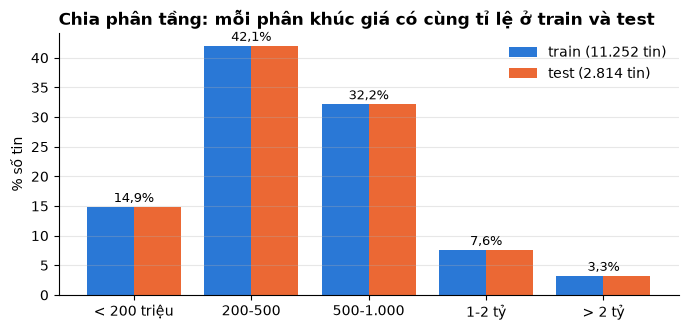

,train (tin),test (tin),train (%),test (%)
phân khúc,,,,
< 200 triệu,1674.0,419.0,14.9,14.9
200-500,4732.0,1183.0,42.1,42.0
500-1.000,3623.0,906.0,32.2,32.2
1-2 tỷ,857.0,214.0,7.6,7.6
> 2 tỷ,366.0,92.0,3.3,3.3
Tổng,11252.0,2814.0,100.0,100.0


In [3]:
seg_share = pd.DataFrame({"train": tr_raw["segment"].value_counts(normalize=True),
                          "test": te_raw["segment"].value_counts(normalize=True)}).reindex(SEG_LABELS) * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(SEG_LABELS))
ax.bar(x - 0.2, seg_share["train"], 0.4, color=BLUE, label=f"train ({vn(len(tr_raw))} tin)")
ax.bar(x + 0.2, seg_share["test"], 0.4, color=ORANGE, label=f"test ({vn(len(te_raw))} tin)")
for i, v in enumerate(seg_share["train"]):
    ax.text(i, v + 0.8, f"{vn(v, 1)}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(SEG_LABELS)
ax.set_ylabel("% số tin"); ax.set_title("Chia phân tầng: mỗi phân khúc giá có cùng tỉ lệ ở train và test", loc="left")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
save(fig, "m01_chia_train_test"); plt.show()

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(x - 0.2, seg_share["train"], 0.4, color=BLUE, label=f"train ({vn(len(tr_raw))} tin)")
    ax.bar(x + 0.2, seg_share["test"], 0.4, color=ORANGE, label=f"test ({vn(len(te_raw))} tin)")
    for i, (a, b) in enumerate(zip(seg_share["train"], seg_share["test"])):
        ax.text(i - 0.2, a + 0.8, f"{vn(a, 1)}%", ha="center", fontsize=12)
        ax.text(i + 0.2, b + 0.8, f"{vn(b, 1)}%", ha="center", fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(SEG_LABELS); ax.set_ylim(0, seg_share.values.max() * 1.18)
    ax.set_ylabel("% số tin"); ax.set_xlabel("phân khúc giá")
    ax.set_title("Chia phân tầng 80/20: mỗi phân khúc giá có cùng tỉ lệ ở train và test")
    ax.legend(frameon=False); ax.grid(axis="x", visible=False)
    save_slide(fig, "m01_chia_train_test"); plt.close(fig)

chia = pd.DataFrame({"train (tin)": tr_raw["segment"].value_counts(), "test (tin)": te_raw["segment"].value_counts()}
                    ).reindex(SEG_LABELS)
chia["train (%)"] = (chia["train (tin)"] / len(tr_raw) * 100).round(1)
chia["test (%)"] = (chia["test (tin)"] / len(te_raw) * 100).round(1)
chia.loc["Tổng"] = [len(tr_raw), len(te_raw), 100.0, 100.0]
chia.index.name = "phân khúc"
save_table(chia, "chia_train_test", "Chia train/test phân tầng theo phân khúc giá", part="process", floatfmt=".1f",
           note="Số tin trước khi lọc giá trả trước / đặt cọc (mục 2).")
chia

## 2. Lọc giá trả trước / đặt cọc, bảng trung vị học từ train

**Hiện tượng** (phân tích ở mục 5.1 của `preprocess_data.ipynb`): nhiều tin ghi ở ô giá **số tiền trả trước hoặc đặt cọc** chứ không phải giá xe, ví dụ xe đời 2025-2026 mà giá chỉ 30-100 triệu. Đây là **nhãn sai** nằm đúng ở biến cần dự đoán.

**Quy tắc:** loại tin có giá **thấp hơn 30% giá trung vị của các xe cùng hãng, dòng và năm sản xuất**, chỉ xét nhóm có ít nhất 3 xe. Không xe nào mất giá 70% so với xe cùng đời chỉ vì tình trạng hay số km.

**Hai chỗ sửa so với phiên bản cũ:**

- **Lỗi logic:** code cũ nhóm cả các tin `carmodel == "Dòng khác"`. Nhãn này trộn nhiều xe không liên quan (một chiếc Mercedes G63 và một chiếc Mercedes đời cũ đều có thể là "Dòng khác"), nên trung vị của nhóm vô nghĩa và có thể loại oan xe rẻ có thật. Giờ **loại "Dòng khác" khỏi bảng tham chiếu**.
- **Rò rỉ dữ liệu:** code cũ tính trung vị trên toàn bộ dữ liệu, tức giá của tập test góp phần quyết định xóa dòng nào khỏi chính tập test. Giờ **bảng trung vị chỉ học từ train**, rồi áp lên cả hai tập.

**Vì sao vẫn xóa dòng ở cả tập test?** Đây là **sửa lỗi nhãn**, không phải cắt ngoại lệ thống kê. Để một nhãn sai trong test thì MAPE không còn đo được chất lượng mô hình: mô hình đoán đúng giá xe nhưng bị chấm sai hàng trăm phần trăm.

**Vì sao lọc trước khi điền thiếu và gộp nhãn?** Quy tắc này chỉ dùng các cột gốc (hãng, dòng, năm, giá), không cần giá trị điền. Lọc trước thì `CarImputer` và `BrandModelGrouper` ở mục 3 được fit trên đúng những dòng sẽ dùng để huấn luyện, các tin có nhãn sai không góp phần vào thống kê.

In [4]:
# Bảng tham chiếu học TỪ TRAIN, bỏ "Dòng khác"
KEY = ["carbrand", "carmodel", "mfdate"]
ref_src = tr_raw[tr_raw["carmodel"] != "Dòng khác"]
g = ref_src.groupby(KEY)["price_tr"]
ref_median = g.median()
ref_size = g.size()
valid_groups = ref_size[ref_size >= 3].index          # nhóm đủ 3 xe mới tin được


def mark_deposit(frame):
    key = pd.MultiIndex.from_frame(frame[KEY])
    med = pd.Series(ref_median.reindex(key).values, index=frame.index)
    ok = pd.Series(key.isin(valid_groups), index=frame.index) & (frame["carmodel"] != "Dòng khác")
    return ok & med.notna() & (frame["price_tr"] < 0.3 * med), med, ok


dep_tr, med_tr, ok_tr = mark_deposit(tr_raw)
dep_te, med_te, ok_te = mark_deposit(te_raw)
print(f"Bảng tham chiếu: {len(valid_groups)} nhóm hãng-dòng-năm có >= 3 xe ở train")
print(f"Loại nghi giá trả trước/đặt cọc: train {dep_tr.sum()}, test {dep_te.sum()}")
print(f"Tin test không có nhóm tham chiếu trong train (không kiểm tra được): {(~ok_te).sum()} "
      f"({(~ok_te).mean():.1%}); trong đó giá < 200 triệu: {((~ok_te) & (te_raw['price_tr'] < 200)).sum()}")

# Để so sánh: quy tắc CŨ (trung vị trên toàn bộ dữ liệu, gồm cả "Dòng khác")
g_old = df.groupby(KEY)["price_tr"]
dep_old = (g_old.transform("size") >= 3) & (df["price_tr"] < 0.3 * g_old.transform("median"))
print(f"Quy tắc cũ (toàn bộ dữ liệu): đánh dấu {dep_old.sum()} tin, trong đó {dep_old.loc[te_raw.index].sum()} tin thuộc test")

examples = (te_raw.loc[dep_te, KEY + ["condition_ad", "price_tr"]].assign(trung_vi_nhom=med_te[dep_te])
            .sort_values("trung_vi_nhom", ascending=False))
display(examples.head(10))

Bảng tham chiếu: 931 nhóm hãng-dòng-năm có >= 3 xe ở train
Loại nghi giá trả trước/đặt cọc: train 99, test 17
Tin test không có nhóm tham chiếu trong train (không kiểm tra được): 594 (21.1%); trong đó giá < 200 triệu: 176
Quy tắc cũ (toàn bộ dữ liệu): đánh dấu 129 tin, trong đó 19 tin thuộc test


,carbrand,carmodel,mfdate,condition_ad,price_tr,trung_vi_nhom
7262,Toyota,Camry,2026,Đã sử dụng,300.0,1360.0
4765,Toyota,Fortuner,2026,Mới,125.0,1275.0
12494,Hyundai,Santa Fe,2025,Mới,220.0,1079.0
9551,Hyundai,Santa Fe,2025,Mới,240.0,1079.0
13991,BYD,Sealion 6,2026,Mới,145.0,884.0
4259,VinFast,MPV 7,2026,Đã sử dụng,80.0,670.0
13666,VinFast,MPV 7,2026,Mới,105.0,670.0
13626,VinFast,Limo Green,2026,Mới,180.0,620.0
4620,VinFast,Limo Green,2026,Mới,59.0,620.0
7405,Mitsubishi,Triton,2025,Đã sử dụng,170.0,585.0


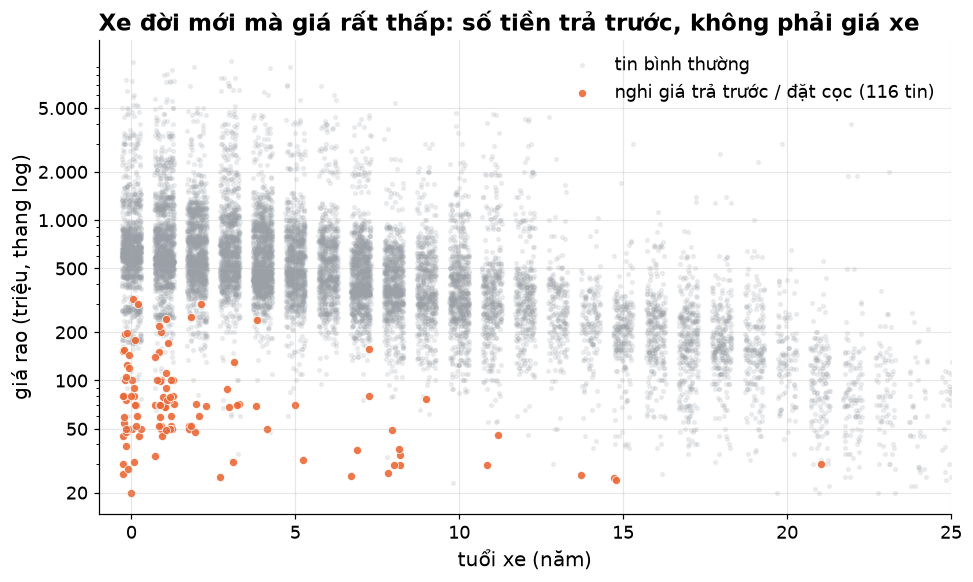

,hãng,dòng xe,năm,tình trạng,giá rao (triệu),trung vị nhóm ở train (triệu)
0,Toyota,Camry,2026,Đã sử dụng,300.0,1360.0
1,Ford,Everest,2026,Đã sử dụng,320.0,1309.5
2,Toyota,Fortuner,2026,Mới,125.0,1275.0
3,Hyundai,Santa Fe,2025,Mới,220.0,1079.0
4,Mercedes Benz,E Class,2019,Đã sử dụng,156.0,899.0


In [5]:
# Minh họa: giá theo tuổi xe, tô màu các tin bị đánh dấu (train + test)
both = pd.concat([tr_raw.assign(dep=dep_tr.values), te_raw.assign(dep=dep_te.values)])
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots()
    jit = np.random.RandomState(RANDOM_STATE).uniform(-0.3, 0.3, len(both))
    ok = ~both["dep"].values
    ax.scatter(both["age"].values[ok] + jit[ok], both["price_tr"].values[ok], s=6, alpha=0.15, color=GRAY,
               label="tin bình thường", rasterized=True)
    ax.scatter(both["age"].values[~ok] + jit[~ok], both["price_tr"].values[~ok], s=28, alpha=0.9, color=ORANGE,
               edgecolor="white", lw=0.5, label=f"nghi giá trả trước / đặt cọc ({vn((~ok).sum())} tin)")
    ax.set_yscale("log"); ax.set_xlim(-1, 25)
    ax.set_yticks([20, 50, 100, 200, 500, 1000, 2000, 5000])
    ax.set_yticklabels(["20", "50", "100", "200", "500", "1.000", "2.000", "5.000"])
    ax.set_xlabel("tuổi xe (năm)"); ax.set_ylabel("giá rao (triệu, thang log)")
    ax.set_title("Xe đời mới mà giá rất thấp: số tiền trả trước, không phải giá xe")
    ax.legend(frameon=False, loc="upper right")
    save(fig, "s08_gia_dat_coc"); save_slide(fig, "s08_gia_dat_coc"); plt.show()

vi_du = (pd.concat([tr_raw.loc[dep_tr].assign(med=med_tr[dep_tr]), te_raw.loc[dep_te].assign(med=med_te[dep_te])])
         .sort_values("med", ascending=False).drop_duplicates(["carbrand", "carmodel"]).head(5))
vi_du = vi_du[["carbrand", "carmodel", "mfdate", "condition_ad", "price_tr", "med"]].rename(columns={
    "carbrand": "hãng", "carmodel": "dòng xe", "mfdate": "năm", "condition_ad": "tình trạng",
    "price_tr": "giá rao (triệu)", "med": "trung vị nhóm ở train (triệu)"}).reset_index(drop=True)
save_table(vi_du, "vi_du_gia_dat_coc", "Ví dụ tin nghi giá trả trước / đặt cọc", part="process", index=False,
           floatfmt=".0f", note="Trung vị nhóm cùng hãng-dòng-năm, học từ train. Giá rao < 30% trung vị thì bị loại.")
vi_du

In [6]:
n_tr0, n_te0 = len(tr_raw), len(te_raw)
tr_raw = tr_raw[~dep_tr.values]
te_raw = te_raw[~dep_te.values]
print(f"Sau khi lọc: train {n_tr0} -> {len(tr_raw)} | test {n_te0} -> {len(te_raw)}")

Sau khi lọc: train 11252 -> 11153 | test 2814 -> 2797


**Ghi chú:**

- Bảng trung vị chỉ học từ train, nên quy tắc này **không dùng biến mục tiêu của test để học bất cứ điều gì**: giá của một tin test chỉ được so với trung vị của các xe train cùng loại.
- Bảng tham chiếu có 931 nhóm hãng-dòng-năm đủ 3 xe ở train. Quy tắc loại **99 tin train và 17 tin test** (còn 11.153 và 2.797).
- **594 tin test (21,1%)** thuộc nhóm hãng-dòng-năm **không có trong train** (hoặc có dưới 3 xe), nên không kiểm tra được và được giữ lại; 176 tin trong số đó có giá dưới 200 triệu. Đây là hạn chế đã biết. Một phần giá trả trước nằm trong nhóm này sẽ lọt vào tập test và làm MAPE cao hơn (xem mục 7.2 của `model.ipynb`).
- So với cách cũ (trung vị trên toàn bộ dữ liệu, kể cả "Dòng khác"): cách cũ đánh dấu 129 tin, trong đó 19 tin thuộc tập test hiện tại; cách mới loại 116 tin (99 + 17). Chênh lệch nhỏ, nhưng giờ giá của tập test không góp phần quyết định xóa dòng nào khỏi chính nó.

## 3. Điền thiếu và gộp nhãn hiếm: fit trên train, transform cả hai tập

Hai transformer tương thích sklearn trong `car_transformers.py` (kiểm tra bằng `python test_transformers.py`):

**`CarImputer`** học trong `fit`: trung vị số km của xe đã dùng theo đời xe (`km_by_year_`), mode kiểu dáng và số chỗ theo hãng + dòng xe (bỏ "Dòng khác"), mode số chỗ theo hãng và toàn cục. `transform` điền thiếu và tạo thêm `mileage_missing` (cờ km được điền), `km_per_year`.

| Cột | Cách điền | Vì sao |
|---|---|---|
| `mileage_km` xe đã dùng | trung vị theo đời xe, + cờ `mileage_missing` | số km lệch phải mạnh nên dùng trung vị; cờ cho mô hình biết đây là ước lượng |
| `cartype` | mode theo dòng xe; không suy được → "Không rõ" | kiểu dáng do dòng xe quyết định; không lùi về hãng vì một hãng bán đủ kiểu dáng |
| `carseats` | mode theo dòng xe → theo hãng → toàn cục | đa số xe 5 chỗ, đoán sai theo hãng thường chỉ lệch 5 ↔ 7 |

**`BrandModelGrouper`** học trong `fit`: danh sách hãng có ≥ 30 tin và tổ hợp hãng + dòng có ≥ 10 tin **ở train**. `transform` tạo `carbrand_grp`, `carmodel_grp`:

| Cấp | Quy tắc | Ví dụ |
|---|---|---|
| Dòng xe | giữ `Hãng + Dòng` nếu có ≥ 10 tin | `Toyota Vios` |
| → Hãng | dòng hiếm hoặc `Dòng khác` → `"<Hãng> - dòng khác"` | `Mercedes Benz - dòng khác` |
| Hãng | giữ hãng nếu có ≥ 30 tin | `Volvo`, `Subaru` |
| → Nhóm hãng | hãng hiếm → `"Hãng cao cấp khác"` hoặc `"Hãng phổ thông khác"` | Bentley → cao cấp; Wuling → phổ thông |

- **Vì sao gộp:** ~70 hãng, ~500 tổ hợp hãng + dòng, nhiều nhãn chỉ 1-5 tin. One-hot nguyên vẹn sinh hàng trăm cột thưa, mô hình học quy luật từ vài mẫu là nhiễu.
- **Vì sao gộp theo cấp:** cách cũ dồn mọi dòng hiếm vào một nhãn `"Dòng khác"` chung, khiến Mercedes G63 và Kia đời cũ cùng nhãn. Lùi về hãng giữ lại thông tin quan trọng nhất còn biết được.
- **Nhóm hãng cao cấp / phổ thông** chia theo **định vị thương hiệu** (danh sách cố định trong `car_transformers.py`), **không** dựa vào giá trong dữ liệu.
- **Nhãn chưa từng thấy ở train** (ví dụ một hãng chỉ xuất hiện ở test) tự rơi về nhóm "khác" tương ứng.

In [7]:
imputer = CarImputer().fit(tr_raw)
grouper = BrandModelGrouper(brand_min=30, model_min=10).fit(tr_raw)


def apply_all(frame):
    return grouper.transform(imputer.transform(frame))


tr = apply_all(tr_raw)
te = apply_all(te_raw)

report = {}
for name, before, after in [("train", tr_raw, tr), ("test", te_raw, te)]:
    report[name] = {
        "số dòng": len(after),
        "km được điền": int(after["mileage_missing"].sum()),
        "cartype được điền theo dòng xe": int((before["cartype"].isna() & (after["cartype"] != "Không rõ")).sum()),
        "cartype → Không rõ": int((after["cartype"] == "Không rõ").sum()),
        "carseats được điền": int(before["carseats"].isna().sum()),
        "nhóm hãng": after["carbrand_grp"].nunique(),
        "nhóm dòng xe": after["carmodel_grp"].nunique(),
    }
report = pd.DataFrame(report).T
print(f"Tham số học từ train: trung vị km cho {len(imputer.km_by_year_)} đời xe (toàn cục {vn(imputer.km_global_)} km); "
      f"{len(grouper.keep_brand_)} hãng và {len(grouper.keep_model_)} dòng xe đủ ngưỡng")
report

Tham số học từ train: trung vị km cho 45 đời xe (toàn cục 70.000 km); 25 hãng và 178 dòng xe đủ ngưỡng


,số dòng,km được điền,cartype được điền theo dòng xe,cartype → Không rõ,carseats được điền,nhóm hãng,nhóm dòng xe
train,11153,653,3443,208,2817,27,196
test,2797,161,884,49,725,27,193


**Tham số học được từ train:** trung vị km xe đã dùng cho 45 đời xe (toàn cục 70.000 km); 25 hãng ≥ 30 tin và 178 dòng xe ≥ 10 tin. Sau khi gộp: train có **27 nhóm hãng, 196 nhóm dòng xe**; test có 27 nhóm hãng, 193 nhóm dòng xe. Số giá trị được điền: km xe cũ 653 (train) / 161 (test), kiểu dáng theo dòng xe 3.443 / 884 (còn 208 / 49 tin → "Không rõ"), số chỗ 2.817 / 725.

`transform` của test dùng **nguyên** các thống kê đã học từ train, nên số nhóm ở test có thể ít hơn train (một số nhóm không có xe nào trong 20% test), và nhãn chưa từng thấy ở train rơi về nhóm "khác" tương ứng. Đó là hành vi đúng: khi triển khai thật, mô hình cũng chỉ biết những gì đã học từ train.

**Kiểm tra bắt buộc:** test không được sinh ra nhóm nhãn nào ngoài những nhóm đã học từ train, và không còn giá trị thiếu ở các cột đặc trưng.

In [8]:
assert set(te["carbrand_grp"]) <= set(tr["carbrand_grp"]), "test sinh nhóm hãng lạ"
assert set(te["carmodel_grp"]) <= set(tr["carmodel_grp"]), "test sinh nhóm dòng xe lạ"
assert tr[["mileage_km", "cartype", "carseats"]].isna().sum().sum() == 0
assert te[["mileage_km", "cartype", "carseats"]].isna().sum().sum() == 0
for frame in (tr, te):
    frame["carseats"] = frame["carseats"].astype(int)
print("OK: nhóm nhãn ở test là tập con của train; không còn thiếu ở mileage_km, cartype, carseats")

rare = tr[tr["carbrand_grp"].isin(["Hãng cao cấp khác", "Hãng phổ thông khác"])]
rare.groupby("carbrand_grp").agg(số_tin=("price_tr", "size"), số_hãng=("carbrand", "nunique"),
                                 giá_trung_vị=("price_tr", "median"),
                                 các_hãng=("carbrand", lambda s: ", ".join(s.value_counts().index[:8])))

OK: nhóm nhãn ở test là tập con của train; không còn thiếu ở mileage_km, cartype, carseats


,số_tin,số_hãng,giá_trung_vị,các_hãng
carbrand_grp,,,,
Hãng cao cấp khác,108,14,1450.0,"Volvo, Jeep, Acura, MINI, Jaguar, Bentley, Inf..."
Hãng phổ thông khác,145,30,379.0,"Skoda, Geely, Wuling, Dongfeng, Ssangyong, Che..."


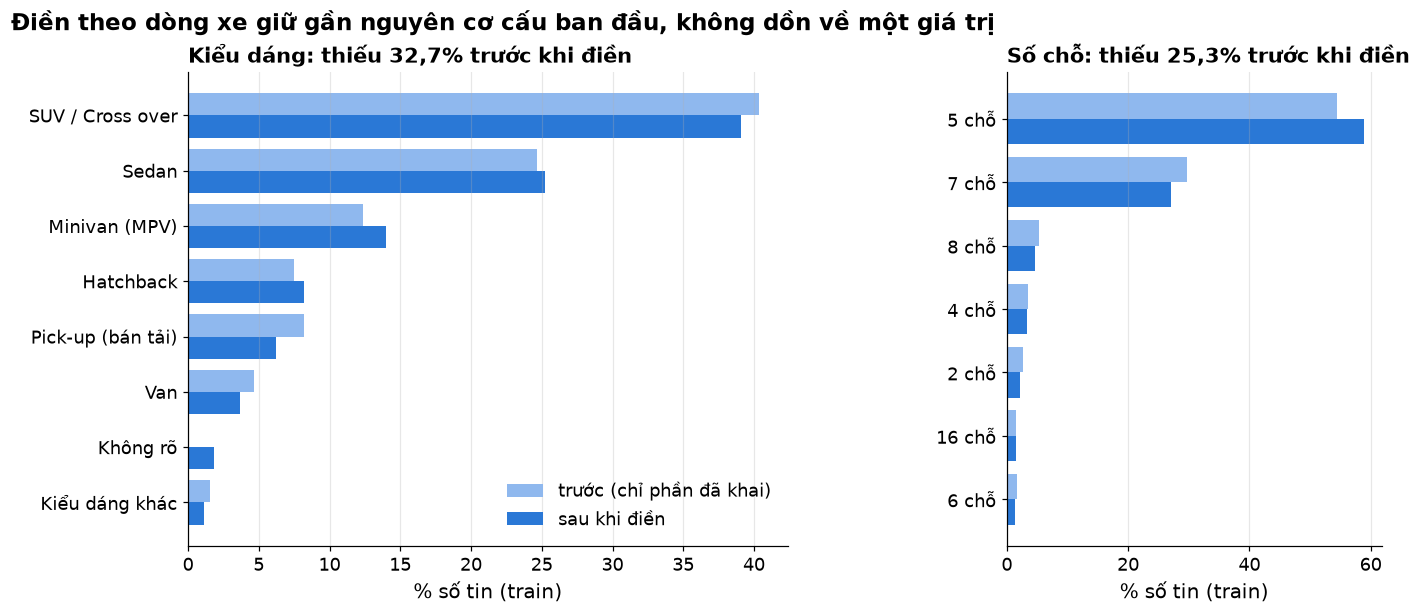

In [9]:
# Kiểm tra: điền theo dòng xe có làm méo cơ cấu kiểu dáng / số chỗ không (train)
def share(series):
    return series.value_counts(normalize=True) * 100

with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.45})
    for ax, col, title, fmt in [(axes[0], "cartype", "Kiểu dáng", str), (axes[1], "carseats", "Số chỗ", lambda v: f"{int(v)} chỗ")]:
        b = share(tr_raw[col].dropna()); a = share(tr[col])
        keys = [k for k in a.sort_values(ascending=False).index if a[k] >= 1 or b.get(k, 0) >= 1]
        yy = np.arange(len(keys))[::-1]
        ax.barh(yy + 0.2, [b.get(k, 0) for k in keys], 0.4, color=LIGHT_BLUE, label="trước (chỉ phần đã khai)")
        ax.barh(yy - 0.2, [a[k] for k in keys], 0.4, color=BLUE, label="sau khi điền")
        ax.set_yticks(yy); ax.set_yticklabels([fmt(k) for k in keys])
        ax.set_xlabel("% số tin (train)"); ax.set_title(f"{title}: thiếu {vn(tr_raw[col].isna().mean() * 100, 1)}% trước khi điền",
                                                        fontsize=14)
        ax.grid(axis="y", visible=False)
    axes[0].legend(frameon=False, loc="lower right")
    fig.suptitle("Điền theo dòng xe giữ gần nguyên cơ cấu ban đầu, không dồn về một giá trị", x=0.01, ha="left",
                 fontsize=15, fontweight="bold")
    save(fig, "s10_truoc_sau_dien_thieu"); save_slide(fig, "s10_truoc_sau_dien_thieu"); plt.show()

## 4. Đặc trưng cho Ridge và khóa nhóm tin đăng lại

`age_sq`, `log_km`, `log_km_per_year` phụ thuộc giá trị số km đã điền nên tính ở đây. Các biến đổi phi tuyến này chỉ cần cho **mô hình tuyến tính** (Ridge), để quan hệ cong (xe mất giá nhanh hơn ở một số giai đoạn, số km lệch phải) trở nên gần tuyến tính. **Mô hình cây** chỉ so sánh ngưỡng nên không bị ảnh hưởng bởi biến đổi đơn điệu: `age` và `age²` mang cùng một thông tin, nên Random Forest không dùng chúng.

`group_key` ghép mọi đặc trưng của tin (kể cả số km) để tìm **tin đăng lại** (dùng ở mục 10 của `model.ipynb`).

> **Lưu ý:** `mileage_km` trong khóa này gồm cả giá trị **đã điền**. Hai xe khác nhau cùng được điền bằng trung vị của một đời xe sẽ trông như "bản sao". Vì vậy tỉ lệ tin có bản sao tính theo khóa này là **giới hạn trên**; bảng dưới báo cả con số chặt hơn (bỏ các dòng có `mileage_missing == 1`).

In [10]:
for frame in (tr, te):
    frame["age_sq"] = frame["age"] ** 2
    frame["log_km"] = np.log1p(frame["mileage_km"])
    frame["log_km_per_year"] = np.log1p(frame["km_per_year"])

FEAT_KEY = ["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox",
            "fuel", "cartype", "carseats", "mfdate", "mileage_km"]
for frame in (tr, te):
    frame["group_key"] = frame[FEAT_KEY].astype(str).agg("|".join, axis=1)

twin = te["group_key"].isin(set(tr["group_key"]))
twin_strict = te["group_key"].isin(set(tr.loc[tr["mileage_missing"] == 0, "group_key"])) & (te["mileage_missing"] == 0)
print(f"Tin test có bản sao trong train: {twin.mean():.1%} (giới hạn trên); "
      f"chỉ tính số km do người bán khai: {twin_strict.mean():.1%}")

Tin test có bản sao trong train: 14.3% (giới hạn trên); chỉ tính số km do người bán khai: 13.1%


## 5. Kiểm chứng cách gộp nhãn và thử vị trí bằng cross-validation trên train

Chuyển nguyên vẹn từ mục 7.4 của phiên bản `preprocess_data.ipynb` cũ. Điểm sửa duy nhất: mỗi phương án gộp nhãn được **fit trên train** (`BrandModelGrouper(...).fit(train)`), không đếm tần suất trên toàn bộ dữ liệu.

So sánh 3 phương án với hai mô hình (Ridge và Random Forest), 5-fold CV phân tầng **chỉ trên train**; bộ mã hóa fit trong từng fold:

- **Cũ:** một nhãn `"Dòng khác"` / `"Hãng khác"` chung, ngưỡng 50 / 30
- **Gộp theo cấp, ngưỡng cũ:** lùi về hãng + tách nhóm hãng, ngưỡng 50 / 30
- **Gộp theo cấp, ngưỡng mới:** như trên, ngưỡng 30 / 10 (phương án được chọn)

Rừng cây dùng 100 cây cho nhanh nên số liệu tuyệt đối hơi khác `model.ipynb`; điều cần xem là **chênh lệch giữa các phương án**.

In [11]:
class OldGrouper(BaseEstimator, TransformerMixin):
    """Cách gộp cũ: một nhãn "Hãng khác" / "Dòng khác" chung cho mọi nhãn hiếm (tần suất đếm trên train)."""

    def __init__(self, brand_min=50, model_min=30):
        self.brand_min, self.model_min = brand_min, model_min

    def fit(self, X, y=None):
        vc_b = X["carbrand"].value_counts()
        self.keep_brand_ = set(vc_b[vc_b >= self.brand_min].index)
        vc_f = (X["carbrand"] + " " + X["carmodel"]).value_counts()
        self.keep_model_ = set(vc_f[vc_f >= self.model_min].index)
        return self

    def transform(self, X):
        X = X.copy()
        full = X["carbrand"] + " " + X["carmodel"]
        X["carbrand_grp"] = X["carbrand"].where(X["carbrand"].isin(self.keep_brand_), "Hãng khác")
        X["carmodel_grp"] = full.where(full.isin(self.keep_model_), "Dòng khác")
        return X


def cv_mape(frame, extra_cat=()):
    # MAPE out-of-fold trên train; bộ mã hóa fit trong từng fold
    d = frame.assign(b=frame["carbrand_grp"], m=frame["carmodel_grp"], log_kpy=frame["log_km_per_year"])
    cat = ["b", "m", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", *extra_cat]
    num = ["age", "age_sq", "log_km", "carseats", "log_kpy"]
    y, p, seg = d["price_log"].values, d["price_tr"].values, d["segment"].values
    res = {}
    for name, make_model in [("Ridge", lambda: Ridge(alpha=0.3)),
                             ("Random Forest", lambda: RandomForestRegressor(100, max_depth=30, max_features=0.33,
                                                                             random_state=RANDOM_STATE, n_jobs=-1))]:
        oof = np.zeros(len(d))
        for a, b in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(d, seg):
            prep = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat), ("n", StandardScaler(), num)])
            m = make_model().fit(prep.fit_transform(d.iloc[a]), y[a])     # fit chỉ trên phần train của fold
            oof[b] = np.exp(m.predict(prep.transform(d.iloc[b])))
        ape = np.abs(oof - p) / p
        res[(name, "MAPE")] = ape.mean()
        res.update({(name, s): ape[seg == s].mean() for s in ["< 200 triệu", "> 2 tỷ"]})
    return res


base = imputer.transform(tr_raw).assign(age_sq=tr["age_sq"].values, log_km=tr["log_km"].values,
                                        log_km_per_year=tr["log_km_per_year"].values)
variants = {
    "Cũ (50 / 30)": OldGrouper(50, 30),
    "Gộp theo cấp (50 / 30)": BrandModelGrouper(50, 30),
    "Gộp theo cấp (30 / 10) - chọn": BrandModelGrouper(30, 10),
}
t0 = time.time()
cmp_rows = {}
for k, gr in variants.items():
    f = gr.fit(tr_raw).transform(base)             # ngưỡng tần suất học từ train
    cmp_rows[k] = {"số nhóm dòng xe": f["carmodel_grp"].nunique(), **cv_mape(f)}
cmp = pd.DataFrame(cmp_rows).T
print(f"{time.time() - t0:.0f}s")
cmp_show = cmp.copy()
cmp_show.columns = [c if isinstance(c, str) else f"{c[0]} - MAPE {c[1]}".replace("MAPE MAPE", "MAPE") for c in cmp.columns]
save_table(cmp_show, "so_sanh_gop_nhan", "So sánh 3 cách gộp nhãn hiếm (5-fold CV trên train)", part="process",
           note="Ridge alpha = 0,3; Random Forest 100 cây, max_depth 30, max_features 0,33.")
cmp_show.round(4)

66s


,số nhóm dòng xe,Ridge - MAPE,Ridge - MAPE < 200 triệu,Ridge - MAPE > 2 tỷ,Random Forest - MAPE,Random Forest - MAPE < 200 triệu,Random Forest - MAPE > 2 tỷ
Cũ (50 / 30),95.0,0.2383,0.5797,0.4788,0.1749,0.4289,0.3294
Gộp theo cấp (50 / 30),114.0,0.2280,0.5429,0.4549,0.1715,0.3997,0.3249
Gộp theo cấp (30 / 10) - chọn,196.0,0.1957,0.4758,0.3395,0.1663,0.3965,0.2941


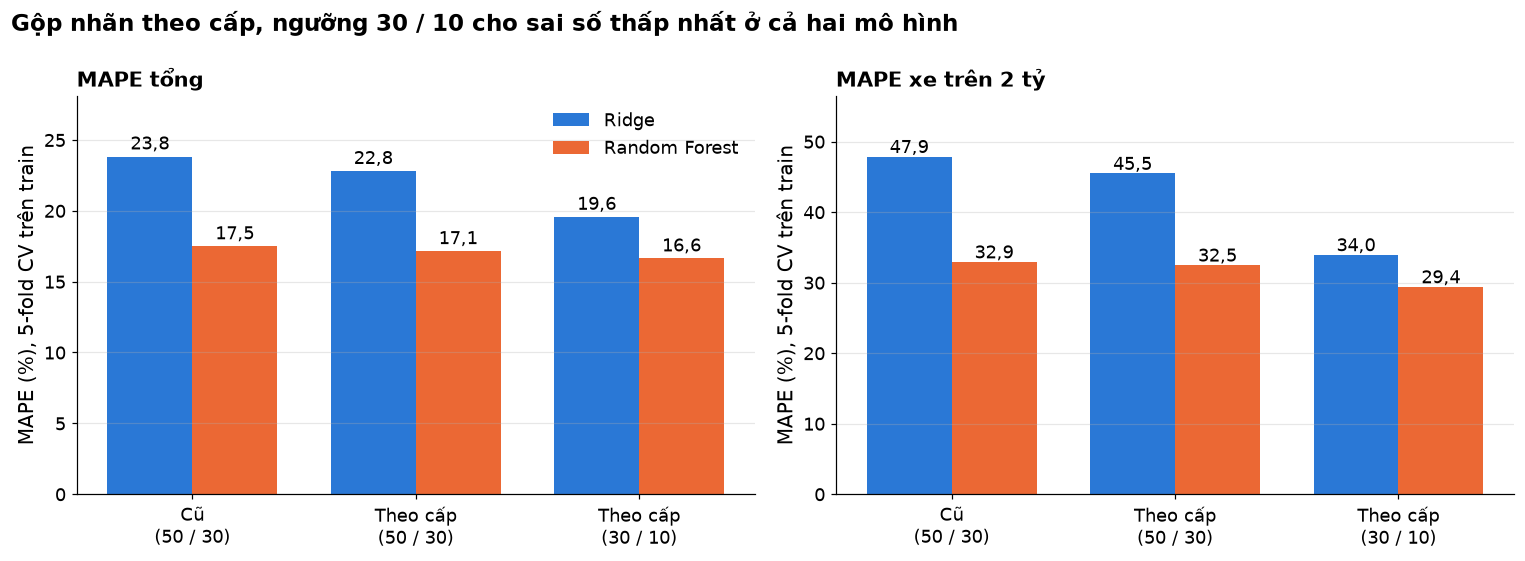

In [12]:
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    labels = ["Cũ\n(50 / 30)", "Theo cấp\n(50 / 30)", "Theo cấp\n(30 / 10)"]
    x = np.arange(3)
    for ax, seg_, title in [(axes[0], "MAPE", "MAPE tổng"), (axes[1], "> 2 tỷ", "MAPE xe trên 2 tỷ")]:
        for k, (mname, color) in enumerate([("Ridge", BLUE), ("Random Forest", ORANGE)]):
            vals = cmp[(mname, seg_)].astype(float).values * 100
            ax.bar(x + (k - 0.5) * 0.38, vals, 0.38, color=color, label=mname)
            for xi, v in zip(x, vals):
                ax.text(xi + (k - 0.5) * 0.38, v + 0.5, vn(v, 1), ha="center", fontsize=12)
        ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_title(title, fontsize=14)
        ax.set_ylabel("MAPE (%), 5-fold CV trên train"); ax.grid(axis="x", visible=False)
        ax.set_ylim(0, cmp[[("Ridge", seg_), ("Random Forest", seg_)]].values.max() * 118)
    axes[0].legend(frameon=False)
    fig.suptitle("Gộp nhãn theo cấp, ngưỡng 30 / 10 cho sai số thấp nhất ở cả hai mô hình", x=0.01, ha="left",
                 fontsize=15, fontweight="bold")
    fig.tight_layout(); save(fig, "s11_gop_nhan"); save_slide(fig, "s11_gop_nhan"); plt.show()

**Đọc kết quả** (MAPE càng thấp càng tốt):
- **Ridge cải thiện rõ rệt:** MAPE tổng giảm từ 23,8% (cách cũ) xuống 22,8% (gộp theo cấp, ngưỡng cũ) rồi 19,6% (ngưỡng 30 / 10); phân khúc > 2 tỷ giảm từ 47,9% xuống 34,0%. Mô hình tuyến tính chỉ có **một hệ số cho mỗi nhãn**. Khi xe sang và xe rẻ bị dồn chung một nhãn `"Dòng khác"`, hệ số đó là mức trung bình vô nghĩa. Lùi về hãng cho mỗi nhóm một mức giá hợp lý hơn.
- **Random Forest cũng cải thiện:** MAPE tổng giảm từ 17,5% xuống 16,6%; phân khúc < 200 triệu từ 42,9% xuống 39,7%, phân khúc > 2 tỷ từ 32,9% xuống 29,4%. Rừng cây vốn bù được một phần thông tin bị mất bằng các đặc trưng khác, nên được lợi ít hơn Ridge.
- Không phương án nào làm mô hình xấu đi. Vì vậy **chọn gộp theo cấp với ngưỡng 30 / 10** (196 nhóm dòng xe ở train). Sai số còn lại ở xe sang chủ yếu do dữ liệu thiếu phiên bản và trang bị xe.

**Có nên dùng vị trí (miền, tỉnh/thành) làm đặc trưng?** Dùng cùng cách đánh giá, cách gộp nhãn đã chọn, chỉ thêm vị trí. Miền suy ra từ tỉnh ngay tại đây (không lưu thành cột). Với tỉnh/thành, các tỉnh có dưới 100 tin **ở train** được gộp thành `"Tỉnh khác - <miền>"`.

In [13]:
NORTH = ("ha-noi hai-phong quang-ninh bac-ninh bac-giang hai-duong hung-yen thai-binh nam-dinh ha-nam ninh-binh "
         "vinh-phuc phu-tho thai-nguyen tuyen-quang ha-giang cao-bang bac-kan lang-son lao-cai yen-bai lai-chau "
         "dien-bien son-la hoa-binh").split()
CENTRAL = ("thanh-hoa nghe-an ha-tinh quang-binh quang-tri thua-thien-hue da-nang quang-nam quang-ngai binh-dinh "
           "phu-yen khanh-hoa ninh-thuan binh-thuan kon-tum gia-lai dak-lak dak-nong lam-dong").split()
SOUTH = ("tp-ho-chi-minh binh-duong dong-nai ba-ria-vung-tau long-an tay-ninh binh-phuoc tien-giang ben-tre "
         "vinh-long tra-vinh dong-thap an-giang kien-giang hau-giang soc-trang bac-lieu ca-mau can-tho").split()
REGION = {**dict.fromkeys(NORTH, "Miền Bắc"), **dict.fromkeys(CENTRAL, "Miền Trung"), **dict.fromkeys(SOUTH, "Miền Nam")}

loc = tr.copy()
loc["region"] = loc["province"].map(REGION).fillna("Không rõ")
prov_vc = loc["province"].value_counts()                     # đếm trên train
loc["province_grp"] = loc["province"].where(loc["province"].map(prov_vc) >= 100, "Tỉnh khác - " + loc["region"])
loc_cmp = pd.DataFrame({
    "Không dùng vị trí": cv_mape(loc),
    "+ miền (3 nhóm)": cv_mape(loc, ["region"]),
    f"+ tỉnh/thành ({loc['province_grp'].nunique()} nhóm)": cv_mape(loc, ["province_grp"]),
}).T
loc_cmp.columns = [f"{a} - MAPE {b}".replace("MAPE MAPE", "MAPE") for a, b in loc_cmp.columns]
save_table(loc_cmp, "thu_vi_tri", "Thử thêm vị trí làm đặc trưng (5-fold CV trên train)", part="process", floatfmt=".4f")
display(loc_cmp.round(4))
print("Giá trung vị theo miền (triệu, train):", loc.groupby("region")["price_tr"].median().to_dict())

,Ridge - MAPE,Ridge - MAPE < 200 triệu,Ridge - MAPE > 2 tỷ,Random Forest - MAPE,Random Forest - MAPE < 200 triệu,Random Forest - MAPE > 2 tỷ
Không dùng vị trí,0.1957,0.4758,0.3395,0.1663,0.3965,0.2941
+ miền (3 nhóm),0.1956,0.4749,0.3401,0.1654,0.3919,0.2969
+ tỉnh/thành (11 nhóm),0.1961,0.4765,0.3404,0.1658,0.3949,0.2979


Giá trung vị theo miền (triệu, train): {'Miền Bắc': 450.0, 'Miền Nam': 480.0, 'Miền Trung': 370.0}


**Kết luận về vị trí:** chênh lệch MAPE giữa ba phương án không quá 0,1 điểm % (Random Forest 16,63% / 16,54% / 16,58%; Ridge 19,57% / 19,56% / 19,61%), nhỏ hơn mức dao động thông thường giữa các lần chia fold. Nghĩa là **vị trí gần như không giúp dự đoán giá**. Điều này hợp lý: giá rao chủ yếu do bản thân chiếc xe quyết định. Giá trung vị ở miền Trung thấp hơn (370 triệu, so với 450 ở miền Bắc và 480 ở miền Nam) chủ yếu do **cơ cấu xe khác nhau** (nhiều xe cũ, rẻ hơn), mà mô hình đã thấy qua các đặc trưng khác. File xuất vẫn giữ `province` để mô tả dữ liệu; mô hình không dùng.

## 6. Đối chứng: điền sẵn so với điền trong từng fold

**Vấn đề còn lại của cấu trúc 3 notebook:** `train_data.csv` chứa giá trị đã điền bằng thống kê của **toàn bộ train**. Khi `model.ipynb` chia train thành nhiều fold để tinh chỉnh, phần validation của mỗi fold đã góp phần tạo ra giá trị điền (trung vị, mode, danh sách nhãn) của chính nó. Ranh giới **train / test** luôn được giữ nghiêm ngặt; điều đang xét chỉ là ranh giới **giữa các fold bên trong train**.

**Thí nghiệm:** cùng một Random Forest (150 cây), cùng 5 fold, chạy hai cách:

- **Điền sẵn:** dùng `tr` đã điền và gộp nhãn (như `model.ipynb` sẽ làm).
- **Điền trong fold:** `CarImputer` + `BrandModelGrouper` nằm trong `Pipeline`, fit lại trên phần train của từng fold, nên phần validation không góp phần gì vào giá trị điền.

Hai cách chạy trên **đúng cùng các dòng** (train đã lọc giá đặt cọc). Nếu MAPE gần nhau thì cách điền sẵn không làm ước lượng CV ở `model.ipynb` lạc quan đáng kể.

In [14]:
CAT = ["carbrand_grp", "carmodel_grp", "carorigin", "condition_ad", "gearbox", "fuel", "cartype"]
NUM = ["age", "mileage_km", "carseats", "km_per_year", "mileage_missing"]
PROBE = dict(n_estimators=150, max_depth=30, max_features=0.33, random_state=RANDOM_STATE, n_jobs=-1)


def encoder():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
                              ("num", "passthrough", NUM)])


def cv_mape_oof(frame_fitted, frame_raw, impute_in_fold):
    """MAPE out-of-fold. impute_in_fold = True thì CarImputer + Grouper fit lại mỗi fold."""
    seg = frame_fitted["segment"].values
    y = frame_fitted["price_log"].values
    p = frame_fitted["price_tr"].values
    oof = np.zeros(len(y))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(frame_fitted, seg):
        if impute_in_fold:
            pipe = Pipeline([("impute", CarImputer()), ("group", BrandModelGrouper(30, 10)),
                             ("encode", encoder()), ("model", RandomForestRegressor(**PROBE))])
            pipe.fit(frame_raw.iloc[a], y[a])
            oof[b] = np.exp(pipe.predict(frame_raw.iloc[b]))
        else:
            pipe = Pipeline([("encode", encoder()), ("model", RandomForestRegressor(**PROBE))])
            pipe.fit(frame_fitted.iloc[a], y[a])
            oof[b] = np.exp(pipe.predict(frame_fitted.iloc[b]))
    ape = np.abs(oof - p) / p
    return {"MAPE": ape.mean(), **{f"MAPE {s}": ape[seg == s].mean() for s in SEG_LABELS}}


tr_raw_cv = tr_raw.reset_index(drop=True)
tr_cv = tr.reset_index(drop=True)
assert len(tr_raw_cv) == len(tr_cv) and (tr_raw_cv["price_tr"].values == tr_cv["price_tr"].values).all()

t0 = time.time()
doi_chung = pd.DataFrame({
    "Điền sẵn (thống kê của toàn bộ train)": cv_mape_oof(tr_cv, tr_raw_cv, impute_in_fold=False),
    "Điền trong từng fold (Pipeline)": cv_mape_oof(tr_cv, tr_raw_cv, impute_in_fold=True),
}).T
doi_chung.loc["Chênh lệch (điểm %)"] = (doi_chung.iloc[1] - doi_chung.iloc[0]) * 100
print(f"{time.time() - t0:.0f}s")
save_table(doi_chung, "doi_chung_cv", "Đối chứng: điền sẵn so với điền trong từng fold (5-fold CV, Random Forest 150 cây)",
           part="process", floatfmt=".4f", note="Hai dòng đầu là MAPE (tỉ lệ); dòng cuối là chênh lệch tính bằng điểm %.")
doi_chung.round(4)

39s


,MAPE,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
Điền sẵn (thống kê của toàn bộ train),0.1681,0.3994,0.1271,0.1071,0.1703,0.2976
Điền trong từng fold (Pipeline),0.1685,0.3990,0.1274,0.1080,0.1715,0.2983
Chênh lệch (điểm %),0.0438,-0.0397,0.0249,0.0835,0.1263,0.0625


**Kết luận:**
- Điền sẵn cho MAPE (CV) **16,81%**, điền lại trong từng fold cho **16,85%**: chênh lệch **0,04 điểm %**, ở từng phân khúc không quá 0,13 điểm %. Mức này nhỏ hơn nhiều so với ngưỡng 0,5 điểm % đặt ra và nhỏ hơn dao động giữa các lần chia fold.
- Vì vậy cấu trúc điền sẵn **không bóp méo kết luận nào**, và các ước lượng CV ở `model.ipynb` (tinh chỉnh tham số, thí nghiệm cân bằng, so sánh mã hóa) dùng được mà không cần đưa `CarImputer` / `BrandModelGrouper` vào `Pipeline`. Lý do chênh lệch nhỏ: các thống kê điền chỉ dùng **đặc trưng**, không dùng giá, và là thống kê theo nhóm lớn.
- Ranh giới **train / test** luôn được giữ nghiêm ngặt trong cả hai cách; chênh lệch ở đây chỉ liên quan tới ranh giới giữa các fold bên trong train.

## 7. Sơ đồ quy trình và xuất file

Sơ đồ tóm tắt thứ tự xử lý: tham số chỉ đi **một chiều** từ train sang test, không có mũi tên ngược.

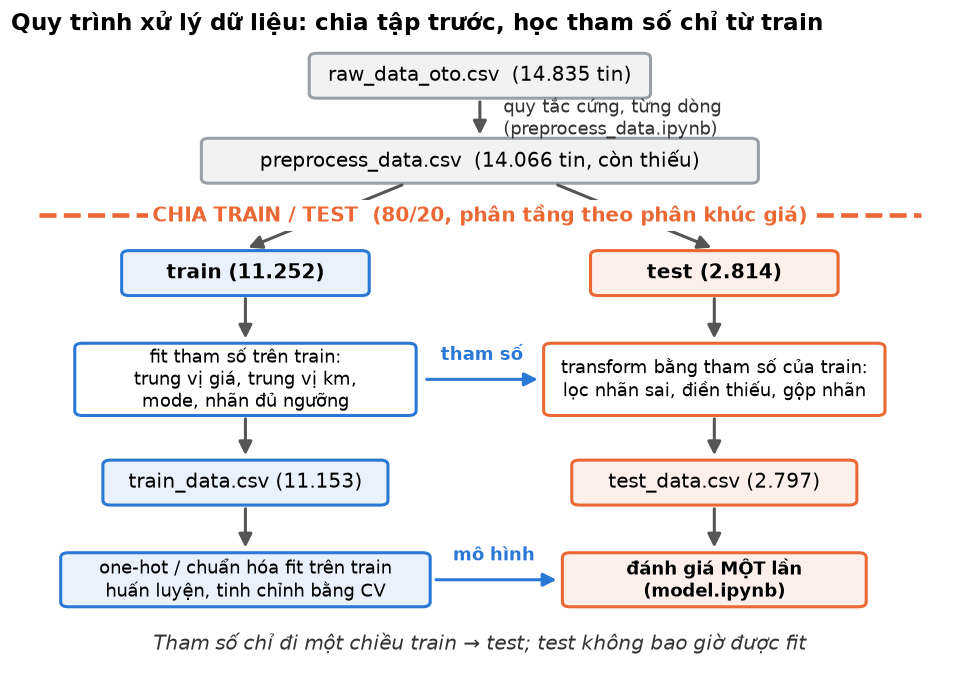

In [15]:
from matplotlib.patches import FancyBboxPatch

FLOW_TXT = """raw_data_oto.csv
      ↓   làm sạch bằng quy tắc cứng, xử lý từng dòng (preprocess_data.ipynb)
preprocess_data.csv          (còn giá trị thiếu)
      ↓   CHIA TRAIN / TEST  (80/20, phân tầng theo phân khúc giá, random_state = 42)
   train          test
      ↓             ↓
  fit tham số → transform     (lọc nhãn sai, điền thiếu, gộp nhãn; process_data.ipynb)
      ↓             ↓
train_data.csv  test_data.csv
      ↓             ↓
   huấn luyện    đánh giá một lần   (model.ipynb: one-hot / chuẩn hóa fit trên train)
"""
Path("tables/so_do_quy_trinh.txt").write_text(FLOW_TXT, encoding="utf-8")


def box(ax, x, y, w, h, text, fc, ec, size=13, bold=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=size, fontweight="bold" if bold else "normal")


def arrow(ax, x0, y0, x1, y1, color="#555555", text=None, dx=0.15):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2,
                                                                  mutation_scale=18))
    if text:
        ax.text((x0 + x1) / 2 + dx, (y0 + y1) / 2, text, fontsize=12, va="center", color="#333333")


with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(11, 7.6))
    ax.set_xlim(0, 10); ax.set_ylim(0, 10.6); ax.axis("off")
    PALE_B, PALE_O, PALE_G = "#e8f1fc", "#fdf0ea", "#f2f2f2"
    box(ax, 5, 10.0, 3.6, 0.7, "raw_data_oto.csv  (14.835 tin)", PALE_G, GRAY)
    arrow(ax, 5, 9.62, 5, 8.98, text="quy tắc cứng, từng dòng\n(preprocess_data.ipynb)", dx=0.25)
    box(ax, 5, 8.6, 5.9, 0.7, f"preprocess_data.csv  ({vn(len(df))} tin, còn thiếu)", PALE_G, GRAY)
    ax.plot([0.3, 9.7], [7.7, 7.7], color=ORANGE, lw=3, ls="--")
    ax.text(5, 7.7, "CHIA TRAIN / TEST  (80/20, phân tầng theo phân khúc giá)", ha="center", va="center", fontsize=13,
            color=ORANGE, fontweight="bold", zorder=5, bbox=dict(fc="white", ec="none", pad=3))
    arrow(ax, 4.2, 8.22, 2.5, 7.15); arrow(ax, 5.8, 8.22, 7.5, 7.15)
    box(ax, 2.5, 6.75, 2.6, 0.7, f"train ({vn(n_tr0)})", PALE_B, BLUE, bold=True)
    box(ax, 7.5, 6.75, 2.6, 0.7, f"test ({vn(n_te0)})", PALE_O, ORANGE, bold=True)
    arrow(ax, 2.5, 6.38, 2.5, 5.62)
    box(ax, 2.5, 5.0, 3.6, 1.15, "fit tham số trên train:\ntrung vị giá, trung vị km,\nmode, nhãn đủ ngưỡng",
        "#ffffff", BLUE, size=12)
    box(ax, 7.5, 5.0, 3.6, 1.15, "transform bằng tham số của train:\nlọc nhãn sai, điền thiếu, gộp nhãn",
        "#ffffff", ORANGE, size=12)
    arrow(ax, 7.5, 6.38, 7.5, 5.62)
    arrow(ax, 4.4, 5.0, 5.65, 5.0, color=BLUE)
    ax.text(5.02, 5.32, "tham số", ha="center", fontsize=12, color=BLUE, fontweight="bold")
    arrow(ax, 2.5, 4.4, 2.5, 3.7); arrow(ax, 7.5, 4.4, 7.5, 3.7)
    box(ax, 2.5, 3.3, 3.0, 0.7, f"train_data.csv ({vn(len(tr))})", PALE_B, BLUE)
    box(ax, 7.5, 3.3, 3.0, 0.7, f"test_data.csv ({vn(len(te))})", PALE_O, ORANGE)
    arrow(ax, 2.5, 2.92, 2.5, 2.18); arrow(ax, 7.5, 2.92, 7.5, 2.18)
    box(ax, 2.5, 1.7, 3.9, 0.85, "one-hot / chuẩn hóa fit trên train\nhuấn luyện, tinh chỉnh bằng CV", PALE_B, BLUE, size=12)
    box(ax, 7.5, 1.7, 3.2, 0.85, "đánh giá MỘT lần\n(model.ipynb)", PALE_O, ORANGE, size=12, bold=True)
    arrow(ax, 4.5, 1.7, 5.85, 1.7, color=BLUE)
    ax.text(5.15, 2.02, "mô hình", ha="center", fontsize=12, color=BLUE, fontweight="bold")
    ax.text(5, 0.55, "Tham số chỉ đi một chiều train → test; test không bao giờ được fit",
            ha="center", fontsize=13, color="#333333", style="italic")
    ax.set_title("Quy trình xử lý dữ liệu: chia tập trước, học tham số chỉ từ train", fontsize=15)
    save(fig, "s06_so_do_quy_trinh"); save_slide(fig, "s06_so_do_quy_trinh"); plt.show()

In [16]:
MODEL_DIR = Path("../model"); MODEL_DIR.mkdir(exist_ok=True)

FINAL_COLS = ["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", "carseats",
              "mfdate", "age", "mileage_km", "province", "price_tr", "price_log"]
EXTRA = ["mileage_missing", "km_per_year", "carbrand_grp", "carmodel_grp", "age_sq", "log_km", "log_km_per_year",
         "segment", "group_key"]
tr = tr[FINAL_COLS + EXTRA].reset_index(drop=True)
te = te[FINAL_COLS + EXTRA].reset_index(drop=True)

tr.to_csv("train_data.csv", index=False)
te.to_csv("test_data.csv", index=False)
joblib.dump({"imputer": imputer, "grouper": grouper, "random_state": RANDOM_STATE,
             "seg_bins": SEG_BINS, "seg_labels": SEG_LABELS,
             "deposit_ref_median": ref_median, "deposit_valid_groups": list(valid_groups)},
            MODEL_DIR / "data_transformers.joblib", compress=3)

FEATURES = CAT + NUM + ["age_sq", "log_km", "log_km_per_year"]
for name, f in [("train_data.csv", tr), ("test_data.csv", te)]:
    back = pd.read_csv(name)
    print(f"{name}: {back.shape}, thiếu ở đặc trưng = {int(back[FEATURES].isna().sum().sum())}, "
          f"thiếu ở province = {int(back['province'].isna().sum())}")
    assert len(back) == len(f)
    assert back[FEATURES].isna().sum().sum() == 0

train_data.csv: (11153, 23), thiếu ở đặc trưng = 0, thiếu ở province = 0
test_data.csv: (2797, 23), thiếu ở đặc trưng = 0, thiếu ở province = 0


**Phải lưu `data_transformers.joblib`.** Hai file CSV chỉ chứa *kết quả* điền, không chứa *tham số* điền. Khi định giá một chiếc xe mới, cần đúng các tham số đã học (trung vị km theo đời xe, danh sách nhãn đủ ngưỡng...). Nếu tính lại từ `train_data.csv` đã điền thì trung vị bị méo, vì chính các giá trị điền được tính vào. `model.ipynb` đọc file này để ghi các tham số vào `metadata.json` cho `price_model.py`.

## 8. Tóm tắt

In [17]:
thong_ke = pd.DataFrame({
    "train": [n_tr0, int(dep_tr.sum()), len(tr), report.loc["train", "km được điền"],
              report.loc["train", "cartype được điền theo dòng xe"], report.loc["train", "cartype → Không rõ"],
              report.loc["train", "carseats được điền"], report.loc["train", "nhóm hãng"], report.loc["train", "nhóm dòng xe"]],
    "test": [n_te0, int(dep_te.sum()), len(te), report.loc["test", "km được điền"],
             report.loc["test", "cartype được điền theo dòng xe"], report.loc["test", "cartype → Không rõ"],
             report.loc["test", "carseats được điền"], report.loc["test", "nhóm hãng"], report.loc["test", "nhóm dòng xe"]],
}, index=["số tin sau khi chia", "loại giá trả trước / đặt cọc", "số tin còn lại", "km xe cũ được điền (cờ = 1)",
          "kiểu dáng điền theo dòng xe", "kiểu dáng → Không rõ", "số chỗ được điền", "nhóm hãng", "nhóm dòng xe"])
save_table(thong_ke, "thong_ke_xu_ly", "Thống kê xử lý dữ liệu sau khi chia tập", part="process", floatfmt=".0f")

tom_tat = pd.DataFrame([
    ("1. Chia train/test", "không (chỉ phân tầng theo phân khúc giá)", f"{vn(n_tr0)} / {vn(n_te0)} tin"),
    ("2. Lọc giá trả trước / đặt cọc", f"bảng trung vị giá {vn(len(valid_groups))} nhóm hãng-dòng-năm",
     f"loại {int(dep_tr.sum())} tin train, {int(dep_te.sum())} tin test"),
    ("3. Điền thiếu (CarImputer)", f"trung vị km {len(imputer.km_by_year_)} đời xe; mode kiểu dáng / số chỗ theo dòng xe",
     f"điền km {report.loc['train', 'km được điền']} / {report.loc['test', 'km được điền']} xe cũ"),
    ("3. Gộp nhãn (BrandModelGrouper)", f"{len(grouper.keep_brand_)} hãng, {len(grouper.keep_model_)} dòng xe đủ ngưỡng",
     f"{report.loc['train', 'nhóm hãng']} nhóm hãng, {report.loc['train', 'nhóm dòng xe']} nhóm dòng xe"),
    ("4. Đặc trưng Ridge, group_key", "không (công thức)", "age², log(km), log(km/năm)"),
    ("5. Thí nghiệm gộp nhãn, vị trí", "CV chỉ trên train", "chọn gộp theo cấp 30 / 10, không dùng vị trí"),
    ("6. Đối chứng điền trong fold", "CV chỉ trên train",
     f"chênh lệch MAPE {vn(doi_chung.loc['Chênh lệch (điểm %)', 'MAPE'], 2)} điểm %"),
    ("7. Xuất file", "", f"train_data.csv {vn(len(tr))} tin, test_data.csv {vn(len(te))} tin"),
], columns=["bước", "tham số học từ train", "ảnh hưởng"])
save_table(tom_tat, "tom_tat_xu_ly", "Tóm tắt các bước xử lý (process_data)", part="process", index=False)
update_numbers(train=len(tr), test=len(te), loai_dat_coc_train=int(dep_tr.sum()), loai_dat_coc_test=int(dep_te.sum()),
               so_tin_sach=len(tr) + len(te), so_nhom_hang=int(report.loc["train", "nhóm hãng"]),
               so_nhom_dong_xe=int(report.loc["train", "nhóm dòng xe"]),
               doi_chung_chenh_lech_diem_pct=round(float(doi_chung.loc["Chênh lệch (điểm %)", "MAPE"]), 3))
display(thong_ke)
tom_tat

,train,test
số tin sau khi chia,11252,2814
loại giá trả trước / đặt cọc,99,17
số tin còn lại,11153,2797
km xe cũ được điền (cờ = 1),653,161
kiểu dáng điền theo dòng xe,3443,884
kiểu dáng → Không rõ,208,49
số chỗ được điền,2817,725
nhóm hãng,27,27
nhóm dòng xe,196,193


,bước,tham số học từ train,ảnh hưởng
0,1. Chia train/test,không (chỉ phân tầng theo phân khúc giá),11.252 / 2.814 tin
1,2. Lọc giá trả trước / đặt cọc,bảng trung vị giá 931 nhóm hãng-dòng-năm,"loại 99 tin train, 17 tin test"
2,3. Điền thiếu (CarImputer),trung vị km 45 đời xe; mode kiểu dáng / số chỗ...,điền km 653 / 161 xe cũ
3,3. Gộp nhãn (BrandModelGrouper),"25 hãng, 178 dòng xe đủ ngưỡng","27 nhóm hãng, 196 nhóm dòng xe"
4,"4. Đặc trưng Ridge, group_key",không (công thức),"age², log(km), log(km/năm)"
5,"5. Thí nghiệm gộp nhãn, vị trí",CV chỉ trên train,"chọn gộp theo cấp 30 / 10, không dùng vị trí"
6,6. Đối chứng điền trong fold,CV chỉ trên train,"chênh lệch MAPE 0,04 điểm %"
7,7. Xuất file,,"train_data.csv 11.153 tin, test_data.csv 2.797..."
